# 07. PSI Monitoring

Goal: measure population stability of the frozen scorecard (`models/scorecard_pipeline.json`).

- Expected (baseline) population: training set
- Observed populations: (a) validation set, expected to show PSI near zero (sanity baseline), (b) `application_test.csv`, a genuinely unseen population used as a proxy for incoming applicants
- Note: the dataset has no calendar dates, so (b) is not true temporal drift. It is the best available proxy for a new population.
- PSI is computed per scorecard characteristic and on the final score, always using the frozen training bins (never recalculated).

Requires `02_feature_engineering.ipynb` to have been run first (it writes `data/processed/train_bureau.csv` and `data/processed/bureau_agg.csv`) and `models/scorecard_pipeline.json` (v1.1).

In [1]:
# Imports, paths and shared scorecard code
import sys
sys.path.append('../src')

import json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from scorecard_utils import score_client

DATA_RAW = '../data/raw/'
DATA_PROC = '../data/processed/'
PIPELINE_PATH = '../models/scorecard_pipeline.json'

with open(PIPELINE_PATH) as f:
    pipeline = json.load(f)
print(pipeline['metadata']['version'], pipeline['metadata']['created'])

1.1 2026-10-30


In [2]:
# Load application_test, defragment first, then replicate the 02 treatment exactly (including .round(1))
app_test = pd.read_csv(DATA_RAW + 'application_test.csv').copy()
app_test['DAYS_EMPLOYED_ANOM'] = (app_test['DAYS_EMPLOYED'] == 365243).astype('int8')
app_test['DAYS_EMPLOYED'] = app_test['DAYS_EMPLOYED'].replace(365243, np.nan)
app_test['AGE_YEARS'] = (-app_test['DAYS_BIRTH'] / 365).round(1)
app_test['YEARS_EMPLOYED'] = (-app_test['DAYS_EMPLOYED'] / 365).round(1)
app_test['YEARS_REGISTRATION'] = (-app_test['DAYS_REGISTRATION'] / 365).round(1)
app_test['YEARS_ID_PUBLISH'] = (-app_test['DAYS_ID_PUBLISH'] / 365).round(1)
app_test['YEARS_LAST_PHONE_CHANGE'] = (-app_test['DAYS_LAST_PHONE_CHANGE'] / 365).round(1)

# Merge with the saved bureau aggregation and check bureau coverage
bureau_agg = pd.read_csv(DATA_PROC + 'bureau_agg.csv')
app_test = app_test.merge(bureau_agg, on='SK_ID_CURR', how='left')
no_bureau = app_test['BUREAU_CREDIT_COUNT'].isnull().mean()
print(app_test.shape, f'no bureau history: {no_bureau:.1%} (train was 14.3%)')

(48744, 155) no bureau history: 13.2% (train was 14.3%)


In [3]:
# Build the 17-variable raw feature frames for train and application_test
FINAL_17_VARS = ['EXT_SOURCE_2', 'EXT_SOURCE_3', 'NAME_EDUCATION_TYPE_BINNED', 'EXT_SOURCE_1',
                 'AMT_CREDIT', 'CODE_GENDER', 'YEARS_EMPLOYED', 'ORGANIZATION_TYPE_BINNED',
                 'FLOORSMAX_AVG', 'BUREAU_CREDIT_ACTIVE_ACTIVE_COUNT',
                 'BUREAU_AMT_CREDIT_SUM_LIMIT_MEAN', 'OCCUPATION_TYPE_BINNED',
                 'REGION_POPULATION_RELATIVE', 'DAYS_ID_PUBLISH',
                 'BUREAU_AMT_CREDIT_SUM_DEBT_MEAN', 'DAYS_LAST_PHONE_CHANGE',
                 'BUREAU_DAYS_CREDIT_MEAN']

# Same RAW_SOURCE as 06: _BINNED variables are fed from the raw Kaggle columns
RAW_SOURCE = {v: v for v in FINAL_17_VARS}
RAW_SOURCE['NAME_EDUCATION_TYPE_BINNED'] = 'NAME_EDUCATION_TYPE'
RAW_SOURCE['ORGANIZATION_TYPE_BINNED'] = 'ORGANIZATION_TYPE'
RAW_SOURCE['OCCUPATION_TYPE_BINNED'] = 'OCCUPATION_TYPE'

def build_X(df):
    return pd.DataFrame({v: df[src] for v, src in RAW_SOURCE.items()})

train_bureau = pd.read_csv(DATA_PROC + 'train_bureau.csv')
X_all = build_X(train_bureau)
X_test = build_X(app_test)
print(X_all.shape, X_test.shape)
print(X_test.isnull().mean().round(3).sort_values(ascending=False).head(8))

(307511, 17) (48744, 17)
FLOORSMAX_AVG                       0.478
EXT_SOURCE_1                        0.421
OCCUPATION_TYPE_BINNED              0.320
BUREAU_AMT_CREDIT_SUM_LIMIT_MEAN    0.219
YEARS_EMPLOYED                      0.190
EXT_SOURCE_3                        0.178
BUREAU_AMT_CREDIT_SUM_DEBT_MEAN     0.153
BUREAU_DAYS_CREDIT_MEAN             0.132
dtype: float64


In [4]:
# Compare missing rates: full train_bureau vs application_test (descriptive, not PSI yet)
miss_cmp = pd.DataFrame({
    'train': X_all.isnull().mean(),
    'test': X_test.isnull().mean(),
})
miss_cmp['diff_pp'] = ((miss_cmp['test'] - miss_cmp['train']) * 100).round(1)
print(miss_cmp.round(3).sort_values('diff_pp', key=abs, ascending=False))

                                   train   test  diff_pp
EXT_SOURCE_1                       0.564  0.421    -14.3
EXT_SOURCE_3                       0.198  0.178     -2.0
FLOORSMAX_AVG                      0.498  0.478     -1.9
BUREAU_AMT_CREDIT_SUM_DEBT_MEAN    0.167  0.153     -1.5
BUREAU_CREDIT_ACTIVE_ACTIVE_COUNT  0.143  0.132     -1.1
BUREAU_DAYS_CREDIT_MEAN            0.143  0.132     -1.1
YEARS_EMPLOYED                     0.180  0.190      1.0
BUREAU_AMT_CREDIT_SUM_LIMIT_MEAN   0.212  0.219      0.8
OCCUPATION_TYPE_BINNED             0.313  0.320      0.7
EXT_SOURCE_2                       0.002  0.000     -0.2
CODE_GENDER                        0.000  0.000      0.0
NAME_EDUCATION_TYPE_BINNED         0.000  0.000      0.0
AMT_CREDIT                         0.000  0.000      0.0
ORGANIZATION_TYPE_BINNED           0.000  0.000      0.0
REGION_POPULATION_RELATIVE         0.000  0.000      0.0
DAYS_ID_PUBLISH                    0.000  0.000      0.0
DAYS_LAST_PHONE_CHANGE         

In [5]:
# EXT_SOURCE_1: distribution of non-missing values, train vs test
es1 = pd.DataFrame({
    'train': X_all['EXT_SOURCE_1'].dropna().describe(),
    'test': X_test['EXT_SOURCE_1'].dropna().describe(),
})
print(es1.round(4))

             train        test
count  134133.0000  28212.0000
mean        0.5021      0.5012
std         0.2111      0.2051
min         0.0146      0.0135
25%         0.3340      0.3437
50%         0.5060      0.5068
75%         0.6751      0.6660
max         0.9627      0.9391


### Coverage check: train vs application_test
Missing rates differ by about 2 percentage points or less for 16 of the 17 variables. EXT_SOURCE_1 is the exception: 56.4% missing in the training data versus 42.1% in application_test. The distribution of its non-missing values is nearly identical (mean 0.502 vs 0.501, median 0.506 vs 0.507), so the shift is in coverage, not in the values. Missing is its own bin for this variable, so PSI is expected to register it (hand estimate before computing: about 0.08).

In [6]:
# Vectorized WoE from the frozen JSON, mirroring score_client rules
def assign_bins(s, spec):
    if spec['type'] == 'numeric':
        idx = pd.cut(s, bins=spec['edges'], labels=False)
        lab = pd.Series(
            np.where(idx.notnull(), 'bin_' + idx.fillna(-1).astype(int).astype(str).str.zfill(2), 'Missing'),
            index=s.index, dtype='object')
        if spec.get('zero_woe') is not None:
            lab = lab.mask(s == 0, 'Zero')
        return lab.mask(s.isnull(), 'Missing')
    cw, cmap = spec['category_woe'], spec.get('category_map')
    c = s.astype('object').where(s.notnull(), 'Missing')
    if cmap is not None:
        fallback = 'Other_grouped' if 'Other_grouped' in cw else ('Missing' if 'Missing' in cw else 'Unmapped')
        c = c.map(cmap).fillna(fallback)
    return c.where(c.isin(list(cw)), 'Unmapped')

def woe_from_labels(lab, spec):
    if spec['type'] == 'numeric':
        m = {f'bin_{i:02d}': w for i, w in enumerate(spec['bin_woe'])}
        m['Zero'] = spec.get('zero_woe')
        m['Missing'] = spec.get('missing_woe')
        return lab.map(m).astype(float)
    m = dict(spec['category_woe'])
    m['Unmapped'] = 0.0
    return lab.map(m).astype(float)

def score_vectorized(X, pipeline):
    V = pipeline['variables']
    lab = pd.DataFrame({v: assign_bins(X[v], sp) for v, sp in V.items()})
    woe = pd.DataFrame({v: woe_from_labels(lab[v], sp) for v, sp in V.items()})
    coef = pd.Series({v: sp['coefficient'] for v, sp in V.items()})
    pts = pipeline['base_points_per_characteristic'] + (-pipeline['factor']) * woe.mul(coef)
    log_odds = woe.mul(coef).sum(axis=1) + pipeline['intercept']
    out = pd.DataFrame({'score': pts.sum(axis=1).round(2),
                        'pd': (1 / (1 + np.exp(-log_odds))).round(4)})
    return lab, woe, out

In [7]:
# Validate vectorized scoring against score_client (fails loudly on any divergence)
sample = X_all.sample(1000, random_state=7)
_, _, vec = score_vectorized(sample, pipeline)
ref = pd.DataFrame(
    [(i, o['score'], o['probability_default'])
     for i, r in sample.iterrows()
     for o in [score_client(r.to_dict(), pipeline)]],
    columns=['idx', 'score_ref', 'pd_ref']).set_index('idx')
cmp = vec.join(ref)
bad = cmp[((cmp['score'] - cmp['score_ref']).abs() > 0.011) | ((cmp['pd'] - cmp['pd_ref']).abs() > 2e-4)]
assert len(bad) == 0, f'{len(bad)} mismatches between vectorized scoring and score_client'
print('OK: 0 mismatches of', len(cmp))

OK: 0 mismatches of 1000


### Vectorized scoring: equivalence with score_client
Scoring hundreds of thousands of clients one at a time with score_client would be slow, so PSI uses a vectorized version of the same rules (bins closed on the right, Zero and Missing overrides, category_map with fallback bucket). On a random sample of 1000 clients both implementations agree (score within 0.011, PD within 2e-4). Writing this check exposed a bug in score_client (a pandas NaN in a categorical column was not treated as Missing), fixed in src/scorecard_utils.py.

In [8]:
# Rebuild the same train/validation split as 06 (same seed) and run two reproducibility checks
y_all = train_bureau['TARGET']
ids = train_bureau['SK_ID_CURR']
X_train, X_val, y_train, y_val = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=42)
print('Train:', X_train.shape, '| Val:', X_val.shape)
print('TARGET rate (train):', y_train.mean().round(4), '| (val):', y_val.mean().round(4))

# Check 1: client 251294 must sit in the validation set, as in 06
print('251294 in validation:', 251294 in set(ids.loc[X_val.index]))

# Check 2: its vectorized score must match the published value (669.48, PD 0.0365)
idx = ids[ids == 251294].index[0]
_, _, one = score_vectorized(X_all.loc[[idx]], pipeline)
print(one)

Train: (246008, 17) | Val: (61503, 17)
TARGET rate (train): 0.0807 | (val): 0.0807
251294 in validation: True
         score      pd
130443  669.48  0.0365


The rebuilt split reproduces 06: same shapes, same TARGET rate, client 251294 in the validation set, and its vectorized score equals the published 669.48 (PD 0.0365).

In [9]:
# Score the three populations with the frozen pipeline (bin labels are kept for the per-variable PSI)
lab_train, woe_train, score_train = score_vectorized(X_train, pipeline)
lab_val, woe_val, score_val = score_vectorized(X_val, pipeline)
lab_test, woe_test, score_test = score_vectorized(X_test, pipeline)

print('NaN WoE (train, val, test):', woe_train.isnull().sum().sum(), woe_val.isnull().sum().sum(), woe_test.isnull().sum().sum())
print('Unmapped categories in test:')
print((lab_test == 'Unmapped').sum().loc[lambda s: s > 0])
print(pd.DataFrame({'train': score_train['score'].describe(),
                    'val': score_val['score'].describe(),
                    'test': score_test['score'].describe()}).round(2))

NaN WoE (train, val, test): 0 0 0
Unmapped categories in test:
Series([], dtype: int64)
           train       val      test
count  246008.00  61503.00  48744.00
mean      500.02    500.18    501.27
std        52.98     52.72     52.90
min       307.13    312.18    320.14
25%       463.24    463.44    464.41
50%       500.83    501.15    502.25
75%       537.38    537.47    538.36
max       687.94    669.48    677.91


In [10]:
# Freeze score bins from the training score: deciles with open outer bins
score_cuts = np.quantile(score_train['score'], np.linspace(0, 1, 11)[1:-1])
score_edges = np.r_[-np.inf, score_cuts, np.inf]
assert len(np.unique(score_cuts)) == 9, 'duplicate score cuts'

def score_bin(s):
    assert s.notnull().all()
    return pd.cut(s, bins=score_edges, labels=False).map(lambda i: f'decile_{int(i) + 1:02d}')

In [11]:
# PSI between an expected and an observed population, over frozen bin labels
def calculate_psi(expected, observed, eps=1e-4):
    cats = sorted(set(expected.unique()) | set(observed.unique()))
    e = expected.value_counts(normalize=True).reindex(cats).fillna(0)
    o = observed.value_counts(normalize=True).reindex(cats).fillna(0)
    e_s, o_s = e.clip(lower=eps), o.clip(lower=eps)   # avoids ln(0) for empty bins
    table = pd.DataFrame({'expected': e, 'observed': o, 'psi_term': (o_s - e_s) * np.log(o_s / e_s)})
    return table['psi_term'].sum(), table

In [12]:
# PSI on the final score and on each of the 17 characteristics (validation and test vs training)
def psi_status(psi):
    return 'stable' if psi < 0.10 else ('moderate' if psi < 0.25 else 'significant')

sc = {name: score_bin(df['score']) for name, df in
      {'train': score_train, 'val': score_val, 'test': score_test}.items()}

rows = [('SCORE', calculate_psi(sc['train'], sc['val'])[0], calculate_psi(sc['train'], sc['test'])[0])]
for v in FINAL_17_VARS:
    rows.append((v, calculate_psi(lab_train[v], lab_val[v])[0], calculate_psi(lab_train[v], lab_test[v])[0]))

psi_df = pd.DataFrame(rows, columns=['variable', 'psi_val', 'psi_test']).set_index('variable')
psi_df['status_test'] = psi_df['psi_test'].map(psi_status)
print(psi_df.sort_values('psi_test', ascending=False).round(4))

                                   psi_val  psi_test status_test
variable                                                        
EXT_SOURCE_1                        0.0004    0.0843      stable
AMT_CREDIT                          0.0001    0.0694      stable
DAYS_ID_PUBLISH                     0.0002    0.0683      stable
DAYS_LAST_PHONE_CHANGE              0.0003    0.0518      stable
EXT_SOURCE_2                        0.0001    0.0150      stable
BUREAU_DAYS_CREDIT_MEAN             0.0001    0.0106      stable
EXT_SOURCE_3                        0.0003    0.0078      stable
YEARS_EMPLOYED                      0.0002    0.0077      stable
ORGANIZATION_TYPE_BINNED            0.0004    0.0050      stable
BUREAU_AMT_CREDIT_SUM_DEBT_MEAN     0.0004    0.0033      stable
REGION_POPULATION_RELATIVE          0.0001    0.0032      stable
FLOORSMAX_AVG                       0.0001    0.0030      stable
BUREAU_CREDIT_ACTIVE_ACTIVE_COUNT   0.0001    0.0022      stable
OCCUPATION_TYPE_BINNED   

In [13]:
# Per-bin view of the four largest test shifts (expected vs observed share, and WoE of each bin)
for v in ['EXT_SOURCE_1', 'AMT_CREDIT', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE']:
    psi, tab = calculate_psi(lab_train[v], lab_test[v])
    tab['woe'] = woe_from_labels(pd.Series(tab.index, index=tab.index), pipeline['variables'][v])
    print(f'{v}: PSI {psi:.4f}')
    print(tab.round(4), '\n')

EXT_SOURCE_1: PSI 0.0843
              expected  observed  psi_term     woe
EXT_SOURCE_1                                      
Missing         0.5634    0.4212    0.0413 -0.0592
bin_00          0.0438    0.0562    0.0031 -0.8755
bin_01          0.0437    0.0522    0.0015 -0.4054
bin_02          0.0435    0.0558    0.0031 -0.1352
bin_03          0.0435    0.0592    0.0048 -0.0493
bin_04          0.0434    0.0643    0.0082  0.1827
bin_05          0.0442    0.0613    0.0055  0.3260
bin_06          0.0434    0.0623    0.0068  0.4767
bin_07          0.0434    0.0596    0.0051  0.6600
bin_08          0.0439    0.0584    0.0041  0.9082
bin_09          0.0436    0.0495    0.0007  1.1978 

AMT_CREDIT: PSI 0.0694
            expected  observed  psi_term     woe
AMT_CREDIT                                      
bin_00        0.1081    0.1288    0.0036  0.1966
bin_01        0.1028    0.1094    0.0004  0.0348
bin_02        0.0892    0.1079    0.0036 -0.0118
bin_03        0.0999    0.1332    0.0096 -

In [14]:
# Decomposition: how much each characteristic moved the mean score (in points), test vs train
coef = pd.Series({v: sp['coefficient'] for v, sp in pipeline['variables'].items()})
pts_train = (-pipeline['factor']) * woe_train.mul(coef)
pts_test = (-pipeline['factor']) * woe_test.mul(coef)
shift = (pts_test.mean() - pts_train.mean()).sort_values(key=abs, ascending=False)
print(shift.round(3))
print('sum:', round(shift.sum(), 3), '| mean score diff:', round(score_test['score'].mean() - score_train['score'].mean(), 3))

EXT_SOURCE_1                         1.243
AMT_CREDIT                          -1.129
EXT_SOURCE_3                        -0.819
YEARS_EMPLOYED                       0.415
NAME_EDUCATION_TYPE_BINNED           0.280
FLOORSMAX_AVG                        0.226
EXT_SOURCE_2                         0.215
DAYS_LAST_PHONE_CHANGE               0.198
DAYS_ID_PUBLISH                      0.158
ORGANIZATION_TYPE_BINNED             0.136
CODE_GENDER                          0.135
OCCUPATION_TYPE_BINNED               0.125
REGION_POPULATION_RELATIVE           0.088
BUREAU_DAYS_CREDIT_MEAN              0.079
BUREAU_AMT_CREDIT_SUM_LIMIT_MEAN    -0.044
BUREAU_AMT_CREDIT_SUM_DEBT_MEAN     -0.028
BUREAU_CREDIT_ACTIVE_ACTIVE_COUNT   -0.027
dtype: float64
sum: 1.251 | mean score diff: 1.251


In [15]:
# DAYS_ID_PUBLISH around the hollow bin_03 (-4171, -3878]: share of each population per 100-day slice
edges = np.arange(-4800, -3500, 100)
cmp = pd.DataFrame({
    'train': pd.cut(X_train['DAYS_ID_PUBLISH'], edges).value_counts(sort=False) / len(X_train),
    'test': pd.cut(X_test['DAYS_ID_PUBLISH'], edges).value_counts(sort=False) / len(X_test),
})
cmp['ratio_test_train'] = cmp['test'] / cmp['train']
print(cmp.round(4))

                  train    test  ratio_test_train
DAYS_ID_PUBLISH                                  
(-4800, -4700]   0.0272  0.0317            1.1640
(-4700, -4600]   0.0322  0.0334            1.0390
(-4600, -4500]   0.0359  0.0380            1.0584
(-4500, -4400]   0.0369  0.0345            0.9364
(-4400, -4300]   0.0382  0.0370            0.9688
(-4300, -4200]   0.0394  0.0432            1.0964
(-4200, -4100]   0.0398  0.0249            0.6254
(-4100, -4000]   0.0393  0.0129            0.3287
(-4000, -3900]   0.0279  0.0134            0.4800
(-3900, -3800]   0.0159  0.0130            0.8218
(-3800, -3700]   0.0136  0.0163            1.1951
(-3700, -3600]   0.0146  0.0172            1.1749


In [16]:
# DAYS_ID_PUBLISH over the full range: share of each population per 250-day slice
edges = np.arange(-7500, 1, 250)
cmp_full = pd.DataFrame({
    'train': pd.cut(X_train['DAYS_ID_PUBLISH'], edges).value_counts(sort=False) / len(X_train),
    'test': pd.cut(X_test['DAYS_ID_PUBLISH'], edges).value_counts(sort=False) / len(X_test),
})
cmp_full['ratio_test_train'] = cmp_full['test'] / cmp_full['train']
print(cmp_full.round(4).to_string())

                  train    test  ratio_test_train
DAYS_ID_PUBLISH                                  
(-7500, -7250]   0.0000  0.0000               NaN
(-7250, -7000]   0.0000  0.0000            0.0000
(-7000, -6750]   0.0000  0.0000               NaN
(-6750, -6500]   0.0000  0.0000            0.0000
(-6500, -6250]   0.0000  0.0008           21.3093
(-6250, -6000]   0.0014  0.0020            1.4011
(-6000, -5750]   0.0023  0.0045            1.9479
(-5750, -5500]   0.0049  0.0064            1.2993
(-5500, -5250]   0.0083  0.0174            2.0912
(-5250, -5000]   0.0239  0.0429            1.7926
(-5000, -4750]   0.0513  0.0691            1.3461
(-4750, -4500]   0.0821  0.0881            1.0739
(-4500, -4250]   0.0948  0.0949            1.0018
(-4250, -4000]   0.0987  0.0575            0.5828
(-4000, -3750]   0.0506  0.0334            0.6604
(-3750, -3500]   0.0387  0.0434            1.1214
(-3500, -3250]   0.0438  0.0370            0.8448
(-3250, -3000]   0.0414  0.0416            1.0058


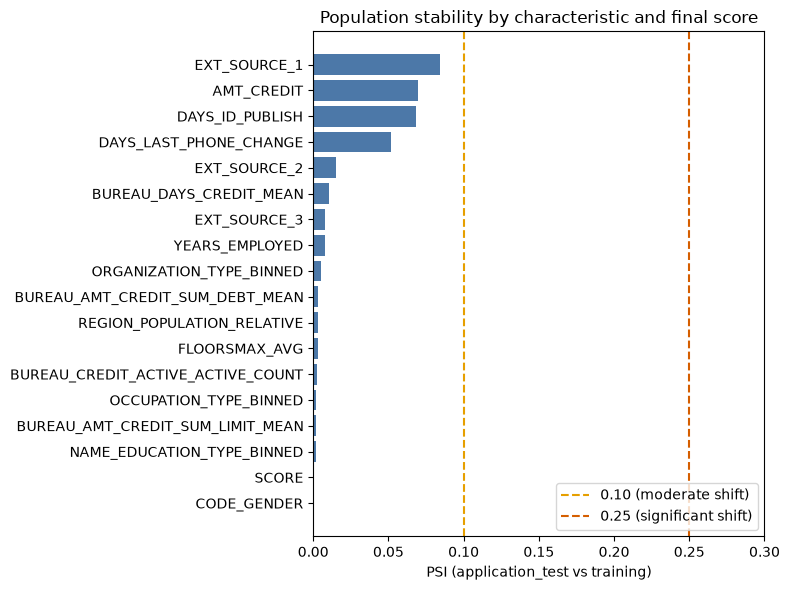

In [17]:
# Bar chart of PSI on application_test vs training, with the conventional 0.10 and 0.25 thresholds
import os
import matplotlib.pyplot as plt

plot_df = psi_df['psi_test'].sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(plot_df.index, plot_df.values, color='#4C78A8')
ax.axvline(0.10, color='#E69F00', linestyle='--', label='0.10 (moderate shift)')
ax.axvline(0.25, color='#D55E00', linestyle='--', label='0.25 (significant shift)')
ax.set_xlabel('PSI (application_test vs training)')
ax.set_title('Population stability by characteristic and final score')
ax.set_xlim(0, 0.30)
ax.legend(loc='lower right')
plt.tight_layout()
os.makedirs('../reports/figures', exist_ok=True)
fig.savefig('../reports/figures/psi_test_by_variable.png', dpi=150)
plt.show()

### Results

- Training vs validation: PSI is at most 0.0004 for every characteristic and 0.0003 for the score, the sampling-noise floor for a random stratified split. This confirms the bins and the PSI code behave as expected.
- Training vs application_test: every characteristic and the final score are below 0.10 (stable by the conventional scale). The score PSI is 0.0007 and the mean score rises by 1.25 points (501.27 vs 500.02, standard deviation about 53).
- The score is stable because individual shifts offset each other. EXT_SOURCE_1 adds +1.24 points (missing share falls from 56.4% to 42.1%), AMT_CREDIT subtracts 1.13 (fewer large credits), EXT_SOURCE_3 subtracts 0.82. A high PSI on a characteristic does not imply an effect on the score: the effect depends on the WoE of the bins where mass moves, times the coefficient.
- Unexplained: DAYS_ID_PUBLISH (PSI 0.068) and DAYS_LAST_PHONE_CHANGE (0.052) show a bin that loses more than half of its mass in application_test while a bin further away gains it. For DAYS_ID_PUBLISH, IDs published 10.3 to 11.6 years before the application fall from 14.9% to 9.1% of the population, and IDs older than 13 years rise from 9.2% to 14.3%. The effect on the score is small (+0.16 points), and the cause could not be established with this dataset.

### Limitations

- application_test is a proxy for a new population, not temporal drift: the dataset has no calendar dates.
- PSI measures changes in the population, not in model performance: application_test has no TARGET, so AUC and KS cannot be recomputed.
- Stable here means no evidence of a population shift between training and application_test. It does not show that the scorecard will remain stable over time in production.